# Ad hoc Black–Scholes implied-volatility smoother  
## Dumas Model S specification

This notebook implements the **ad hoc Black–Scholes** comparison from Dumas, Fleming and Whaley.

It is not their deterministic volatility function (DVF) model.

The procedure is:

1. obtain a Black–Scholes implied volatility for each calibration quote;
2. smooth those IVs across forward moneyness and maturity;
3. insert the fitted IV back into the ordinary Black–Scholes formula;
4. freeze today's fitted function for the one-day-ahead prediction.

Dumas's Model S switches its polynomial according to how many expiries are present:

$$
\begin{aligned}
\text{one expiry:}\quad
\sigma &= \beta_0+\beta_1m+\beta_2m^2,\\
\text{two expiries:}\quad
\sigma &= \beta_0+\beta_1m+\beta_2m^2+\beta_3T+\beta_4mT,\\
\text{three or more expiries:}\quad
\sigma &= \beta_0+\beta_1m+\beta_2m^2+\beta_3T+\beta_4T^2+\beta_5mT,
\end{aligned}
$$

where $m=K/F-1$.

The main implementation below is paper-faithful in form and uses ordinary least squares in IV space. A cubic smoothing-spline experiment is included only as an optional extension at the end.

A “pair” is the same option contract (`optionid`) observed on date t and again on the next trading day t+1, so its one-day pricing and hedging errors can be measured.

# Shared IvyDB preparation for the SPX benchmarks

This notebook uses the same deliberately small data pipeline as the other benchmark notebook.

The common market universe is called `quotes_all`. It keeps both ITM and OTM options. OTM selection is **not** a permanent cleaning rule.

A second table, `calibration_quotes`, is used to calibrate the model. Its default is OTM-only because:

- OTM options usually have more reliable time value and implied volatility;
- using both an ITM option and its OTM put–call-parity counterpart adds largely repeated information;
- local-volatility, Heston and neural-SDE calibrations can later use the same OTM calibration universe.

The final evaluation table is built from `quotes_all`, so pricing and hedging can still be reported over the wider clean universe.

For later model comparisons, retain the identifier

```text
pair_id = date | date_next | optionid
```

and compare models only on the intersection of their available `pair_id` values.

## 1. Imports, filenames and a few visible choices

The settings below are intentionally limited. They determine the common sample and should remain unchanged across flat BS, ad hoc BS, local volatility, Heston and neural SDE.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq, minimize_scalar
from scipy.stats import norm

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

DATA_FOLDER = Path(".")

OPTIONS_FILE = DATA_FOLDER / "one_month_spx_option_price.csv"
SPOT_FILE = DATA_FOLDER / "one_month_spx_security_price.csv"
FORWARD_FILE = DATA_FOLDER / "one_month_spx_forward_price.csv"
RATE_FILE = DATA_FOLDER / "one_month_spx_zero_coupon_yield_curve.csv"

TARGET_SECID = 108105

MIN_DTE = 14
MAX_DTE = 365
MAX_ABS_LOG_MONEYNESS = 0.30
MAX_RELATIVE_SPREAD = 0.50

# OTM-only calibration is a modelling choice, not a permanent data deletion.
CALIBRATE_ON_OTM_ONLY = True

print("Imports and settings completed.")

Imports and settings completed.


## 2. Load the four raw CSV files

Each table has one role:

- `options_raw`: SPX option quotes;
- `spot_raw`: the daily SPX index level;
- `forwards_raw`: the forward index level for each expiry and settlement convention;
- `rates_raw`: the zero-coupon curve for each quote date.

Security Name History is not needed after confirming that SPX has `secid = 108105`.

In [2]:
options_raw = pd.read_csv(OPTIONS_FILE, low_memory=False)
spot_raw = pd.read_csv(SPOT_FILE)
forwards_raw = pd.read_csv(FORWARD_FILE)
rates_raw = pd.read_csv(RATE_FILE)

print("Raw shapes")
print("options: ", options_raw.shape)
print("spot:    ", spot_raw.shape)
print("forwards:", forwards_raw.shape)
print("rates:   ", rates_raw.shape)

Raw shapes
options:  (326964, 27)
spot:     (20, 7)
forwards: (1192, 7)
rates:    (220, 3)


## 3. Basic option cleaning

This block performs only the cleaning needed for a valid common benchmark:

1. parse dates and numeric columns;
2. divide IvyDB `strike_price` by 1,000;
3. construct midpoint and spread;
4. retain standard European SPX contracts;
5. remove invalid or very wide quotes;
6. retain 14–365 days to expiry.

The standard SPX contract multiplier is **100**. The separate factor of **1,000** applies only to IvyDB's stored strike.

In [3]:
options = options_raw.copy()

# The Option Prices table contains a forward_price column in this download,
# but it is entirely missing. The separate Forward Price table is used below.
if "forward_price" in options.columns:
    options = options.drop(columns=["forward_price"])

options["date"] = pd.to_datetime(options["date"], errors="coerce")
options["exdate"] = pd.to_datetime(options["exdate"], errors="coerce")

numeric_columns = [
    "secid",
    "strike_price",
    "best_bid",
    "best_offer",
    "impl_volatility",
    "delta",
    "vega",
    "optionid",
    "am_settlement",
    "contract_size",
]

for column in numeric_columns:
    if column in options.columns:
        options[column] = pd.to_numeric(options[column], errors="coerce")

options["strike"] = options["strike_price"] / 1000.0
options["mid"] = (options["best_bid"] + options["best_offer"]) / 2.0
options["spread"] = options["best_offer"] - options["best_bid"]
options["relative_spread"] = options["spread"] / options["mid"]
options["dte"] = (options["exdate"] - options["date"]).dt.days
options["T"] = options["dte"] / 365.0

standard_contract = (
    options["ss_flag"].astype(str).isin(["0", "0.0"])
    & options["contract_size"].eq(100)
)

valid_quote = (
    options["best_bid"].gt(0)
    & options["best_offer"].ge(options["best_bid"])
    & options["mid"].gt(0)
    & options["relative_spread"].le(MAX_RELATIVE_SPREAD)
)

basic_keep = (
    options["secid"].eq(TARGET_SECID)
    & options["exercise_style"].astype(str).str.upper().eq("E")
    & options["cp_flag"].isin(["C", "P"])
    & standard_contract
    & valid_quote
    & options["strike"].gt(0)
    & options["dte"].between(MIN_DTE, MAX_DTE)
)

rows_before = len(options)
options = options.loc[basic_keep].copy()

duplicate_count = options.duplicated(["optionid", "date"]).sum()
if duplicate_count > 0:
    raise ValueError(
        f"Found {duplicate_count} duplicate (optionid, date) observations. "
        "Resolve these before continuing."
    )

print(f"Rows before basic cleaning: {rows_before:,}")
print(f"Rows after basic cleaning:  {len(options):,}")

Rows before basic cleaning: 326,964
Rows after basic cleaning:  316,297


## 4. Clean and merge spot and forward prices

The merge keys are:

- spot: `(secid, date)`;
- forward: `(secid, date, exdate, am_settlement)`.

The settlement flag is essential because AM- and PM-settled SPX contracts can share the same calendar expiry.

In [4]:
spot = spot_raw.copy()
spot["date"] = pd.to_datetime(spot["date"], errors="coerce")
spot["secid"] = pd.to_numeric(spot["secid"], errors="coerce")
spot["close"] = pd.to_numeric(spot["close"], errors="coerce")

spot = (
    spot.loc[spot["secid"].eq(TARGET_SECID), ["secid", "date", "close"]]
    .rename(columns={"close": "spot"})
    .copy()
)

if spot.duplicated(["secid", "date"]).any():
    raise ValueError("Security Prices is not unique on (secid, date).")

forwards = forwards_raw.rename(
    columns={
        "expiration": "exdate",
        "AMSettlement": "am_settlement",
        "ForwardPrice": "forward_price",
    }
).copy()

forwards["date"] = pd.to_datetime(forwards["date"], errors="coerce")
forwards["exdate"] = pd.to_datetime(forwards["exdate"], errors="coerce")
forwards["secid"] = pd.to_numeric(forwards["secid"], errors="coerce")
forwards["am_settlement"] = pd.to_numeric(
    forwards["am_settlement"], errors="coerce"
)
forwards["forward_price"] = pd.to_numeric(
    forwards["forward_price"], errors="coerce"
)

forwards = forwards.loc[
    forwards["secid"].eq(TARGET_SECID),
    ["secid", "date", "exdate", "am_settlement", "forward_price"],
].copy()

forward_key = ["secid", "date", "exdate", "am_settlement"]

if forwards.duplicated(forward_key).any():
    raise ValueError(
        "Forward Prices is not unique after including AM settlement."
    )

options = options.merge(
    spot,
    on=["secid", "date"],
    how="left",
    validate="many_to_one",
)

options = options.merge(
    forwards,
    on=forward_key,
    how="left",
    validate="many_to_one",
)

print("Missing spot values:   ", options["spot"].isna().sum())
print("Missing forward values:", options["forward_price"].isna().sum())

Missing spot values:    0
Missing forward values: 0


## 5. Interpolate the zero rate

IvyDB supplies rates at selected maturities. For an option whose maturity lies between curve points, we linearly interpolate.

The downloaded rates are in percentage points, so `5.30` becomes `0.0530`.

This notebook treats the zero rate as continuously compounded:

$$
D(t,T)=e^{-rT}.
$$

The maturity filter keeps options inside the downloaded curve range, so the interpolation is not intended to extrapolate.

In [5]:
rates = rates_raw.copy()
rates["date"] = pd.to_datetime(rates["date"], errors="coerce")
rates["days"] = pd.to_numeric(rates["days"], errors="coerce")
rates["rate"] = pd.to_numeric(rates["rate"], errors="coerce")
rates["rate_decimal"] = rates["rate"] / 100.0

options["rate"] = np.nan

for date in options["date"].dropna().unique():
    rows_today = options["date"].eq(date)
    curve_today = rates.loc[rates["date"].eq(date)].sort_values("days")

    if curve_today.empty:
        continue

    dte_today = options.loc[rows_today, "dte"]

    inside_curve = (
        dte_today.ge(curve_today["days"].min())
        & dte_today.le(curve_today["days"].max())
    )

    valid_indices = dte_today.index[inside_curve]

    options.loc[valid_indices, "rate"] = np.interp(
        options.loc[valid_indices, "dte"],
        curve_today["days"],
        curve_today["rate_decimal"],
    )

options["discount"] = np.exp(-options["rate"] * options["T"])

print("Missing interpolated rates:", options["rate"].isna().sum())

Missing interpolated rates: 0


## 6. Final common quote universe

Forward moneyness is

$$
m=\frac{K}{F}-1,
$$

and log-forward moneyness is

$$
k=\log\left(\frac{K}{F}\right).
$$

Dumas defines moneyness using $K/F-1$, so the Dumas ad hoc specification later uses `moneyness`.

At this stage we:

- require matched spot, forward and rate;
- keep a moderate log-moneyness range;
- remove midpoint prices outside elementary European no-arbitrage bounds;
- label OTM options without deleting ITM options.

The result, `quotes_all`, is the shared cleaned universe.

In [6]:
options = options.dropna(
    subset=[
        "date",
        "exdate",
        "optionid",
        "spot",
        "forward_price",
        "rate",
        "discount",
    ]
).copy()

options["moneyness"] = options["strike"] / options["forward_price"] - 1.0
options["log_moneyness"] = np.log(
    options["strike"] / options["forward_price"]
)

is_call = options["cp_flag"].eq("C")
is_put = options["cp_flag"].eq("P")

options["is_otm"] = (
    (is_call & options["strike"].ge(options["forward_price"]))
    | (is_put & options["strike"].lt(options["forward_price"]))
)

options["lower_bound"] = np.where(
    is_call,
    options["discount"]
    * np.maximum(options["forward_price"] - options["strike"], 0.0),
    options["discount"]
    * np.maximum(options["strike"] - options["forward_price"], 0.0),
)

options["upper_bound"] = np.where(
    is_call,
    options["discount"] * options["forward_price"],
    options["discount"] * options["strike"],
)

inside_bounds = (
    options["mid"].gt(options["lower_bound"] + 1e-10)
    & options["mid"].lt(options["upper_bound"] - 1e-10)
)

common_keep = (
    options["log_moneyness"].abs().le(MAX_ABS_LOG_MONEYNESS)
    & inside_bounds
)

quotes_all = options.loc[common_keep].copy()
quotes_all = quotes_all.sort_values(["date", "optionid"]).reset_index(drop=True)

if CALIBRATE_ON_OTM_ONLY:
    calibration_quotes = quotes_all.loc[quotes_all["is_otm"]].copy()
else:
    calibration_quotes = quotes_all.copy()

print(f"Common clean quotes: {len(quotes_all):,}")
print(f"Calibration quotes:  {len(calibration_quotes):,}")
print(f"OTM share of common quotes: {quotes_all['is_otm'].mean():.2%}")
print(f"Dates: {quotes_all['date'].nunique()}")
print(f"Contracts: {quotes_all['optionid'].nunique()}")

Common clean quotes: 243,997
Calibration quotes:  125,746
OTM share of common quotes: 51.54%
Dates: 20
Contracts: 18290


## 7. Common spread statistics

These statistics describe `quotes_all`, not a model-specific subset.

Average bid–ask spread: 3.4692
Median bid–ask spread:  0.8000
Average relative spread: 2.39%
0.500     0.8
0.750     6.6
0.900     8.6
0.950    10.8
0.995    21.1
Name: spread, dtype: float64
Min spread: 0.04999999999999982
Max spread: 72.0


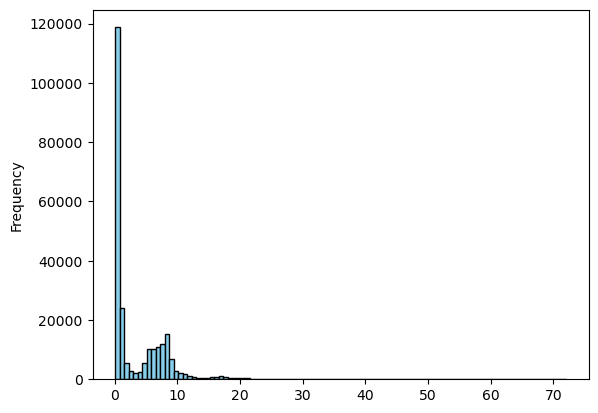

In [7]:
average_spread = quotes_all["spread"].mean()
median_spread = quotes_all["spread"].median()
average_relative_spread = quotes_all["relative_spread"].mean()

print(f"Average bid–ask spread: {average_spread:.4f}")
print(f"Median bid–ask spread:  {median_spread:.4f}")
print(f"Average relative spread: {average_relative_spread:.2%}")

# post-cleaning options

quotes_all["spread"].plot(kind="hist", bins=100, edgecolor="black", color="skyblue")
print(quotes_all["spread"].quantile([0.5, 0.75, 0.9, 0.95, 0.995]))

print("Min spread:", min(quotes_all["spread"]))
print("Max spread:", max(quotes_all["spread"]))

## 8. Black–Scholes price and delta

Both benchmark notebooks use the same forward-form Black–Scholes functions.

For a call,

$$
C=D\left(FN(d_1)-KN(d_2)\right).
$$

The spot delta is recovered from the observed relation between spot and forward:

$$
\Delta_{\mathrm{call}}=D\frac{F}{S}N(d_1).
$$

This keeps the option-pricing inputs consistent with the separate IvyDB forward table.

In [8]:
def bs_price(cp_flag, forward, strike, T, discount, sigma):
    cp_flag = np.asarray(cp_flag)
    forward = np.asarray(forward, dtype=float)
    strike = np.asarray(strike, dtype=float)
    T = np.asarray(T, dtype=float)
    discount = np.asarray(discount, dtype=float)
    sigma = np.asarray(sigma, dtype=float)

    sqrt_T = np.sqrt(T)

    d1 = (
        np.log(forward / strike)
        + 0.5 * sigma**2 * T
    ) / (sigma * sqrt_T)

    d2 = d1 - sigma * sqrt_T

    call = discount * (
        forward * norm.cdf(d1)
        - strike * norm.cdf(d2)
    )

    put = discount * (
        strike * norm.cdf(-d2)
        - forward * norm.cdf(-d1)
    )

    return np.where(cp_flag == "C", call, put)


def bs_delta(cp_flag, spot, forward, strike, T, discount, sigma):
    cp_flag = np.asarray(cp_flag)
    spot = np.asarray(spot, dtype=float)
    forward = np.asarray(forward, dtype=float)
    strike = np.asarray(strike, dtype=float)
    T = np.asarray(T, dtype=float)
    discount = np.asarray(discount, dtype=float)
    sigma = np.asarray(sigma, dtype=float)

    sqrt_T = np.sqrt(T)

    d1 = (
        np.log(forward / strike)
        + 0.5 * sigma**2 * T
    ) / (sigma * sqrt_T)

    carry = discount * forward / spot

    call_delta = carry * norm.cdf(d1)
    put_delta = carry * (norm.cdf(d1) - 1.0)

    return np.where(cp_flag == "C", call_delta, put_delta)

## 9. Build the common one-trading-day evaluation pairs

This step uses `quotes_all`, not `calibration_quotes`.

A quote on date $t$ is paired with the same `optionid` on the next date in the SPX trading calendar. Reappearance after a longer gap is not treated as a one-day observation.

The resulting `evaluation_pairs` is the common candidate universe for every benchmark.

In [9]:
trading_dates = sorted(spot["date"].dropna().unique())

next_date_map = {
    trading_dates[i]: trading_dates[i + 1]
    for i in range(len(trading_dates) - 1)
}

today = quotes_all.copy()
today["date_next"] = today["date"].map(next_date_map)
today = today.dropna(subset=["date_next"]).copy()

tomorrow_columns = [
    "optionid",
    "date",
    "exdate",
    "cp_flag",
    "strike",
    "mid",
    "best_bid",
    "best_offer",
    "spot",
    "forward_price",
    "rate",
    "discount",
    "T",
    "dte",
    "moneyness",
    "log_moneyness",
    "is_otm",
]

tomorrow = quotes_all[tomorrow_columns].copy()

tomorrow = tomorrow.rename(
    columns={
        "date": "date_next",
        "exdate": "exdate_next",
        "cp_flag": "cp_flag_next",
        "strike": "strike_next",
        "mid": "mid_next",
        "best_bid": "best_bid_next",
        "best_offer": "best_offer_next",
        "spot": "spot_next",
        "forward_price": "forward_price_next",
        "rate": "rate_next",
        "discount": "discount_next",
        "T": "T_next",
        "dte": "dte_next",
        "moneyness": "moneyness_next",
        "log_moneyness": "log_moneyness_next",
        "is_otm": "is_otm_next",
    }
)

evaluation_pairs = today.merge(
    tomorrow,
    on=["optionid", "date_next"],
    how="inner",
    validate="one_to_one",
)

evaluation_pairs["pair_id"] = (
    evaluation_pairs["date"].dt.strftime("%Y-%m-%d")
    + "|"
    + evaluation_pairs["date_next"].dt.strftime("%Y-%m-%d")
    + "|"
    + evaluation_pairs["optionid"].astype("Int64").astype(str)
)

evaluation_pairs["option_change"] = (
    evaluation_pairs["mid_next"] - evaluation_pairs["mid"]
)

print(f"Common candidate one-day pairs: {len(evaluation_pairs):,}")
print(f"Current dates represented: {evaluation_pairs['date'].nunique()}")

Common candidate one-day pairs: 224,566
Current dates represented: 19


## 10. Common metric helper

The helper reports:

- midpoint RMSE and MAE;
- proportion inside each quote's own bid–ask interval;
- average distance outside the interval;
- hedging RMSE, MAE and bias where a hedge-error column is supplied.

It does not change the data.

In [10]:
def summarise_model(
    data,
    price_error_column,
    model_price_column,
    hedge_error_column=None,
):
    price_error = data[price_error_column]

    inside_bid_ask = data[model_price_column].between(
        data["best_bid_next"],
        data["best_offer_next"],
    )

    outside_spread_error = np.maximum(
        data["best_bid_next"] - data[model_price_column],
        data[model_price_column] - data["best_offer_next"],
    )
    outside_spread_error = np.maximum(outside_spread_error, 0.0)

    result = {
        "number_of_pairs": len(data),
        "next_day_price_rmse": np.sqrt(np.mean(price_error**2)),
        "next_day_price_mae": np.mean(np.abs(price_error)),
        "next_day_inside_bid_ask": inside_bid_ask.mean(),
        "next_day_outside_spread_mae": outside_spread_error.mean(),
        "unhedged_mae": data["option_change"].abs().mean(),
    }

    if hedge_error_column is not None:
        hedge_error = data[hedge_error_column]

        result["hedging_rmse"] = np.sqrt(np.mean(hedge_error**2))
        result["hedging_mae"] = np.mean(np.abs(hedge_error))
        result["hedging_bias"] = hedge_error.mean()
        result["hedging_improvement"] = (
            1.0
            - result["hedging_mae"] / result["unhedged_mae"]
        )

    return pd.Series(result)

# Ad hoc BS model

## 11. Use IvyDB IV and recover missing calibration IVs

The original paper recovered implied volatility from option prices. IvyDB already provides it for most observations.

For the calibration set only:

1. keep a valid supplied IV;
2. invert the midpoint when the IV is missing or invalid;
3. exclude the small number of rows where inversion fails.

`quotes_all` itself is not reduced by missing supplied IV because those contracts can still be evaluated after a surface has been fitted.

In [11]:
def implied_volatility(row):
    market_price = row["mid"]
    cp = row["cp_flag"]
    F = row["forward_price"]
    K = row["strike"]
    T = row["T"]
    D = row["discount"]

    def error(sigma):
        model_price = bs_price(cp, F, K, T, D, sigma)
        return float(model_price - market_price)

    try:
        return brentq(error, 0.001, 5.0)
    except ValueError:
        return np.nan


calibration_quotes = calibration_quotes.copy()

calibration_quotes["market_iv"] = pd.to_numeric(
    calibration_quotes["impl_volatility"],
    errors="coerce",
)

valid_supplied_iv = calibration_quotes["market_iv"].between(0.001, 5.0)
missing_iv = ~valid_supplied_iv

print(f"IVs to recover: {missing_iv.sum():,}")

calibration_quotes.loc[missing_iv, "market_iv"] = (
    calibration_quotes.loc[missing_iv]
    .apply(implied_volatility, axis=1)
)

before_iv_filter = len(calibration_quotes)

calibration_quotes = calibration_quotes.loc[
    calibration_quotes["market_iv"].between(0.001, 5.0)
].copy()

print(f"Calibration quotes before IV filter: {before_iv_filter:,}")
print(f"Calibration quotes after IV filter:  {len(calibration_quotes):,}")

IVs to recover: 0
Calibration quotes before IV filter: 125,746
Calibration quotes after IV filter:  125,746


## 12. Fit Dumas Model S each day

The response variable is market implied volatility.

The explanatory variables are selected according to the number of distinct expiries in that day's calibration cross-section.

Ordinary least squares chooses coefficients that minimise

$$
\sum_i
\left(
\sigma_i^{market}
-
\sigma^{Model\,S}(m_i,T_i)
\right)^2.
$$

This is an implied-volatility smoothing objective, not a direct price-error objective.

In [12]:
def design_matrix(m, T, specification):
    columns = [
        np.ones(len(m)),
        m,
        m**2,
    ]

    if specification in ["AH2", "AH3"]:
        columns.append(T)

    if specification == "AH3":
        columns.append(T**2)

    if specification in ["AH2", "AH3"]:
        columns.append(m * T)

    return np.column_stack(columns)


coefficient_rows = []

for date, daily_quotes in calibration_quotes.groupby("date"):
    number_of_expiries = daily_quotes["exdate"].nunique()

    if number_of_expiries == 1:
        specification = "AH1"
        minimum_quotes = 15
    elif number_of_expiries == 2:
        specification = "AH2"
        minimum_quotes = 25
    else:
        specification = "AH3"
        minimum_quotes = 30

    if len(daily_quotes) < minimum_quotes:
        continue

    m = daily_quotes["moneyness"].to_numpy()
    T = daily_quotes["T"].to_numpy()
    y = daily_quotes["market_iv"].to_numpy()

    X = design_matrix(m, T, specification)
    beta = np.linalg.lstsq(X, y, rcond=None)[0]

    # Store every possible coefficient. Terms absent from AH1/AH2 are zero.
    row = {
        "date": date,
        "specification": specification,
        "number_of_expiries": number_of_expiries,
        "calibration_quotes": len(daily_quotes),
        "beta_0": beta[0],
        "beta_m": beta[1],
        "beta_m2": beta[2],
        "beta_T": 0.0,
        "beta_T2": 0.0,
        "beta_mT": 0.0,
    }

    if specification == "AH2":
        row["beta_T"] = beta[3]
        row["beta_mT"] = beta[4]

    if specification == "AH3":
        row["beta_T"] = beta[3]
        row["beta_T2"] = beta[4]
        row["beta_mT"] = beta[5]

    coefficient_rows.append(row)

model_s_parameters = pd.DataFrame(coefficient_rows)

print("Dates fitted:", len(model_s_parameters))
print(model_s_parameters["specification"].value_counts())
model_s_parameters.head()

Dates fitted: 20
specification
AH3    20
Name: count, dtype: int64


,date,specification,number_of_expiries,calibration_quotes,beta_0,beta_m,beta_m2,beta_T,beta_T2,beta_mT
0,2024-03-01,AH3,36,5934,0.129544,-0.611188,1.475866,-0.078130,0.096967,0.630206
1,2024-03-04,AH3,36,6205,0.135744,-0.603352,1.517071,-0.095060,0.112524,0.638609
2,2024-03-05,AH3,36,6191,0.145222,-0.623841,1.466852,-0.109300,0.118948,0.641168
3,2024-03-06,AH3,36,6156,0.144060,-0.637556,1.431027,-0.109357,0.123731,0.670818
4,2024-03-07,AH3,36,6108,0.144201,-0.623093,1.459373,-0.117735,0.132676,0.661754


## 13. Same-day fitted IV, price and plug-in delta

The fitted polynomial is evaluated for every row in `quotes_all`, including ITM observations.

The fitted IV is clipped to a small positive interval only so Black–Scholes remains numerically defined. The clipping is a computational safeguard; it does not make the surface arbitrage-free.

The hedge uses the ordinary Black–Scholes delta evaluated at fitted IV. It does not differentiate the fitted smile with respect to spot.

In [13]:
model_s_quotes = quotes_all.merge(
    model_s_parameters,
    on="date",
    how="inner",
)

model_s_quotes["fitted_iv_raw"] = (
    model_s_quotes["beta_0"]
    + model_s_quotes["beta_m"] * model_s_quotes["moneyness"]
    + model_s_quotes["beta_m2"] * model_s_quotes["moneyness"]**2
    + model_s_quotes["beta_T"] * model_s_quotes["T"]
    + model_s_quotes["beta_T2"] * model_s_quotes["T"]**2
    + model_s_quotes["beta_mT"]
      * model_s_quotes["moneyness"]
      * model_s_quotes["T"]
)

model_s_quotes["fitted_iv"] = model_s_quotes["fitted_iv_raw"].clip(
    0.01,
    3.00,
)

model_s_quotes["model_price"] = bs_price(
    model_s_quotes["cp_flag"],
    model_s_quotes["forward_price"],
    model_s_quotes["strike"],
    model_s_quotes["T"],
    model_s_quotes["discount"],
    model_s_quotes["fitted_iv"],
)

model_s_quotes["model_delta"] = bs_delta(
    model_s_quotes["cp_flag"],
    model_s_quotes["spot"],
    model_s_quotes["forward_price"],
    model_s_quotes["strike"],
    model_s_quotes["T"],
    model_s_quotes["discount"],
    model_s_quotes["fitted_iv"],
)

model_s_quotes["same_day_price_error"] = (
    model_s_quotes["model_price"] - model_s_quotes["mid"]
)

same_day_inside = model_s_quotes["model_price"].between(
    model_s_quotes["best_bid"],
    model_s_quotes["best_offer"],
)

same_day_outside = np.maximum(
    model_s_quotes["best_bid"] - model_s_quotes["model_price"],
    model_s_quotes["model_price"] - model_s_quotes["best_offer"],
)
same_day_outside = np.maximum(same_day_outside, 0.0)

print(
    "Same-day price RMSE:",
    np.sqrt(np.mean(model_s_quotes["same_day_price_error"] ** 2)),
)
print(
    "Same-day price MAE:",
    model_s_quotes["same_day_price_error"].abs().mean(),
)
print("Same-day inside bid-ask:", same_day_inside.mean())
print("Same-day outside-spread MAE:", same_day_outside.mean())

Same-day price RMSE: 10.960276185925682
Same-day price MAE: 6.806371198274684
Same-day inside bid-ask: 0.15916589138391046
Same-day outside-spread MAE: 5.404208614893837


## 14. Plot one daily Model S fit

Each line is one expiry available on March 1st, 2024. The dots are market IV observations and the lines are values from the single daily Model S polynomial.

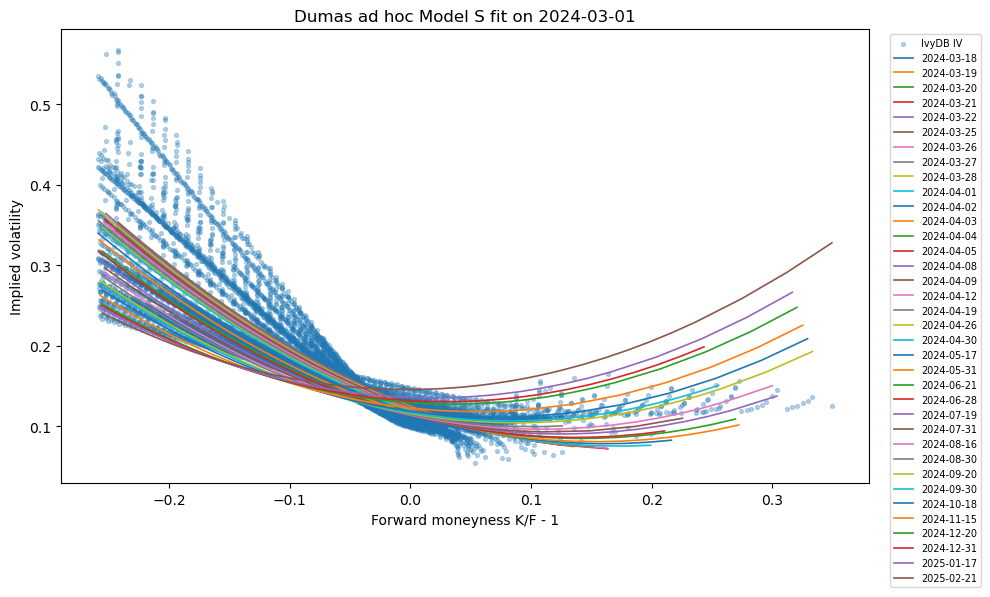

In [14]:
example_date = model_s_quotes["date"].min()

example = model_s_quotes.loc[
    model_s_quotes["date"].eq(example_date)
].copy()

plt.figure(figsize=(10, 6))

plt.scatter(
    example["moneyness"],
    example["impl_volatility"],
    s=8,
    alpha=0.30,
    label="IvyDB IV",
)

for exdate, expiry_quotes in example.groupby("exdate"):
    expiry_quotes = expiry_quotes.sort_values("moneyness")

    plt.plot(
        expiry_quotes["moneyness"],
        expiry_quotes["fitted_iv"],
        linewidth=1.2,
        label=str(exdate.date()),
    )

plt.title(f"Dumas ad hoc Model S fit on {example_date.date()}")
plt.xlabel("Forward moneyness K/F - 1")
plt.ylabel("Implied volatility")
plt.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 15. Frozen one-day-ahead pricing

The date-$t$ coefficients are frozen.

They are evaluated at date $t+1$ using tomorrow's forward moneyness and remaining maturity. Tomorrow's option quote is used only to measure the error, not to refit the surface.

In [15]:
model_s_pairs = evaluation_pairs.merge(
    model_s_quotes[
        [
            "date",
            "optionid",
            "specification",
            "beta_0",
            "beta_m",
            "beta_m2",
            "beta_T",
            "beta_T2",
            "beta_mT",
            "fitted_iv",
            "model_delta",
            "model_price",
        ]
    ],
    on=["date", "optionid"],
    how="inner",
    validate="one_to_one",
)

model_s_pairs["predicted_iv_next_raw"] = (
    model_s_pairs["beta_0"]
    + model_s_pairs["beta_m"] * model_s_pairs["moneyness_next"]
    + model_s_pairs["beta_m2"] * model_s_pairs["moneyness_next"]**2
    + model_s_pairs["beta_T"] * model_s_pairs["T_next"]
    + model_s_pairs["beta_T2"] * model_s_pairs["T_next"]**2
    + model_s_pairs["beta_mT"]
      * model_s_pairs["moneyness_next"]
      * model_s_pairs["T_next"]
)

model_s_pairs["predicted_iv_next"] = (
    model_s_pairs["predicted_iv_next_raw"].clip(0.01, 3.00)
)

model_s_pairs["predicted_price_next"] = bs_price(
    model_s_pairs["cp_flag_next"],
    model_s_pairs["forward_price_next"],
    model_s_pairs["strike_next"],
    model_s_pairs["T_next"],
    model_s_pairs["discount_next"],
    model_s_pairs["predicted_iv_next"],
)

model_s_pairs["next_day_price_error"] = (
    model_s_pairs["predicted_price_next"] - model_s_pairs["mid_next"]
)

print(
    "Next-day price RMSE:",
    np.sqrt(np.mean(model_s_pairs["next_day_price_error"] ** 2)),
)
print(
    "Next-day price MAE:",
    model_s_pairs["next_day_price_error"].abs().mean(),
)

Next-day price RMSE: 10.99679708898309
Next-day price MAE: 6.922372971395274


## 16. One-day delta hedge

The same common hedge error is used:

$$
\varepsilon_{t+1}
=
(C_{t+1}-C_t)
-
\Delta_t(S_{t+1}-S_t).
$$

This makes the hedge results directly comparable with flat BS and, later, LV, Heston and neural SDE.

In [16]:
model_s_pairs["hedging_error"] = (
    model_s_pairs["option_change"]
    - model_s_pairs["model_delta"]
      * (model_s_pairs["spot_next"] - model_s_pairs["spot"])
)

model_s_summary = summarise_model(
    model_s_pairs,
    price_error_column="next_day_price_error",
    model_price_column="predicted_price_next",
    hedge_error_column="hedging_error",
)

model_s_summary

number_of_pairs                224566.000000
next_day_price_rmse                10.996797
next_day_price_mae                  6.922373
next_day_inside_bid_ask             0.154939
next_day_outside_spread_mae         5.521707
unhedged_mae                       13.058954
hedging_rmse                        2.357259
hedging_mae                         1.717112
hedging_bias                       -0.133942
hedging_improvement                 0.868511
dtype: float64

## 17. All-option and OTM-only reporting

In [17]:
model_s_comparison = pd.DataFrame(
    {
        "all_clean_options": summarise_model(
            model_s_pairs,
            "next_day_price_error",
            "predicted_price_next",
            "hedging_error",
        ),
        "otm_only": summarise_model(
            model_s_pairs.loc[model_s_pairs["is_otm"]],
            "next_day_price_error",
            "predicted_price_next",
            "hedging_error",
        ),
    }
).T

model_s_comparison

,number_of_pairs,next_day_price_rmse,next_day_price_mae,next_day_inside_bid_ask,next_day_outside_spread_mae,unhedged_mae,hedging_rmse,hedging_mae,hedging_bias,hedging_improvement
all_clean_options,224566.0,10.996797,6.922373,0.154939,5.521707,13.058954,2.357259,1.717112,-0.133942,0.868511
otm_only,115993.0,10.166925,6.027968,0.022208,5.791591,4.568611,1.459936,1.012155,-0.019610,0.778455


## 18. Save the paper-faithful main result

The main exported result is Dumas Model S. The optional spline experiment below is saved separately and should not replace the paper-faithful label.

In [18]:
output_folder = Path("ad_hoc_bs_outputs")
output_folder.mkdir(exist_ok=True)

model_s_parameters.to_csv(
    output_folder / "dumas_model_s_daily_parameters.csv",
    index=False,
)

model_s_pairs.to_csv(
    output_folder / "dumas_model_s_pair_results.csv",
    index=False,
)

model_s_comparison.to_csv(
    output_folder / "dumas_model_s_summary.csv",
)

evaluation_pairs[["pair_id", "date", "date_next", "optionid"]].to_csv(
    output_folder / "common_candidate_pair_keys.csv",
    index=False,
)

print("Saved main outputs to:", output_folder.resolve())

Saved main outputs to: C:\Users\Startklar\ICL\NDEs\Codes\BS-IVF\ad_hoc_bs_outputs


# Extension: cubic smoothing spline

This section is **not** Dumas Model S.

It fits a separate cubic smoothing spline for each date and expiry using log-forward moneyness. It is useful for diagnosing whether Model S fails because its global polynomial is too stiff.

Important cautions:

- `s=0` is interpolation rather than genuine smoothing;
- a flexible spline can fit quote noise;
- frozen next-day evaluation must not extrapolate outside yesterday's fitted range;
- spline results may therefore use fewer pairs and must be compared with other models on a common `pair_id` intersection.

Set `RUN_SPLINE_EXTENSION = True` to run it.

In [19]:
RUN_SPLINE_EXTENSION = True
SPLINE_SMOOTHING = 0.0001

In [20]:
if RUN_SPLINE_EXTENSION:
    from scipy.interpolate import UnivariateSpline

    spline_models = {}
    spline_rows = []

    spline_calibration = calibration_quotes.copy()

    for (date, exdate), group in spline_calibration.groupby(
        ["date", "exdate"]
    ):
        smile = (
            group.groupby("log_moneyness", as_index=False)
            .agg(market_iv=("market_iv", "mean"))
            .sort_values("log_moneyness")
        )

        if len(smile) < 8:
            continue

        k = smile["log_moneyness"].to_numpy()
        iv = smile["market_iv"].to_numpy()

        spline = UnivariateSpline(
            k,
            iv,
            k=3,
            s=SPLINE_SMOOTHING,
        )

        spline_models[(date, exdate)] = {
            "spline": spline,
            "k_min": k.min(),
            "k_max": k.max(),
        }

    spline_quotes = quotes_all.copy()
    spline_quotes["spline_iv"] = np.nan

    for (date, exdate), indices in spline_quotes.groupby(
        ["date", "exdate"]
    ).groups.items():
        model = spline_models.get((date, exdate))

        if model is None:
            continue

        k = spline_quotes.loc[indices, "log_moneyness"]
        inside_range = k.between(model["k_min"], model["k_max"])
        valid_indices = k.index[inside_range]

        spline_quotes.loc[valid_indices, "spline_iv"] = model["spline"](
            spline_quotes.loc[valid_indices, "log_moneyness"]
        )

    spline_quotes = spline_quotes.dropna(subset=["spline_iv"]).copy()
    spline_quotes["spline_iv"] = spline_quotes["spline_iv"].clip(0.01, 3.0)

    spline_quotes["model_price"] = bs_price(
        spline_quotes["cp_flag"],
        spline_quotes["forward_price"],
        spline_quotes["strike"],
        spline_quotes["T"],
        spline_quotes["discount"],
        spline_quotes["spline_iv"],
    )

    spline_quotes["model_delta"] = bs_delta(
        spline_quotes["cp_flag"],
        spline_quotes["spot"],
        spline_quotes["forward_price"],
        spline_quotes["strike"],
        spline_quotes["T"],
        spline_quotes["discount"],
        spline_quotes["spline_iv"],
    )

    spline_pairs = evaluation_pairs.merge(
        spline_quotes[
            ["date", "optionid", "model_price", "model_delta"]
        ],
        on=["date", "optionid"],
        how="inner",
        validate="one_to_one",
    )

    def previous_spline_iv(row):
        model = spline_models.get((row["date"], row["exdate"]))

        if model is None:
            return np.nan

        k_next = row["log_moneyness_next"]

        if k_next < model["k_min"] or k_next > model["k_max"]:
            return np.nan

        return float(model["spline"](k_next))

    spline_pairs["predicted_iv_next"] = spline_pairs.apply(
        previous_spline_iv,
        axis=1,
    )

    spline_pairs = spline_pairs.dropna(
        subset=["predicted_iv_next"]
    ).copy()

    spline_pairs["predicted_iv_next"] = (
        spline_pairs["predicted_iv_next"].clip(0.01, 3.0)
    )

    spline_pairs["predicted_price_next"] = bs_price(
        spline_pairs["cp_flag_next"],
        spline_pairs["forward_price_next"],
        spline_pairs["strike_next"],
        spline_pairs["T_next"],
        spline_pairs["discount_next"],
        spline_pairs["predicted_iv_next"],
    )

    spline_pairs["next_day_price_error"] = (
        spline_pairs["predicted_price_next"]
        - spline_pairs["mid_next"]
    )

    spline_pairs["hedging_error"] = (
        spline_pairs["option_change"]
        - spline_pairs["model_delta"]
          * (spline_pairs["spot_next"] - spline_pairs["spot"])
    )

    spline_summary = summarise_model(
        spline_pairs,
        "next_day_price_error",
        "predicted_price_next",
        "hedging_error",
    )

    display(spline_summary)

    spline_pairs.to_csv(
        output_folder / "optional_spline_pair_results.csv",
        index=False,
    )

    spline_summary.to_frame("value").to_csv(
        output_folder / "optional_spline_summary.csv"
    )

number_of_pairs                223866.000000
next_day_price_rmse                 6.047277
next_day_price_mae                  4.343949
next_day_inside_bid_ask             0.151144
next_day_outside_spread_mae         2.760363
unhedged_mae                       13.059909
hedging_rmse                        2.296419
hedging_mae                         1.664897
hedging_bias                       -0.158295
hedging_improvement                 0.872518
dtype: float64

In [21]:
spline_quotes["same_day_price_error"] = (
    spline_quotes["model_price"] - spline_quotes["mid"]
)

same_day_inside = spline_quotes["model_price"].between(
    spline_quotes["best_bid"],
    spline_quotes["best_offer"],
)

same_day_outside = np.maximum(
    spline_quotes["best_bid"] - spline_quotes["model_price"],
    spline_quotes["model_price"] - spline_quotes["best_offer"],
)
same_day_outside = np.maximum(same_day_outside, 0.0)

print(
    "Same-day price RMSE:",
    np.sqrt(np.mean(spline_quotes["same_day_price_error"] ** 2)),
)
print(
    "Same-day price MAE:",
    spline_quotes["same_day_price_error"].abs().mean(),
)
print("Same-day inside bid-ask:", same_day_inside.mean())
print("Same-day outside-spread MAE:", same_day_outside.mean())

Same-day price RMSE: 5.717455688826412
Same-day price MAE: 3.7289757029901307
Same-day inside bid-ask: 0.3886521797968448
Same-day outside-spread MAE: 2.1686334263293996


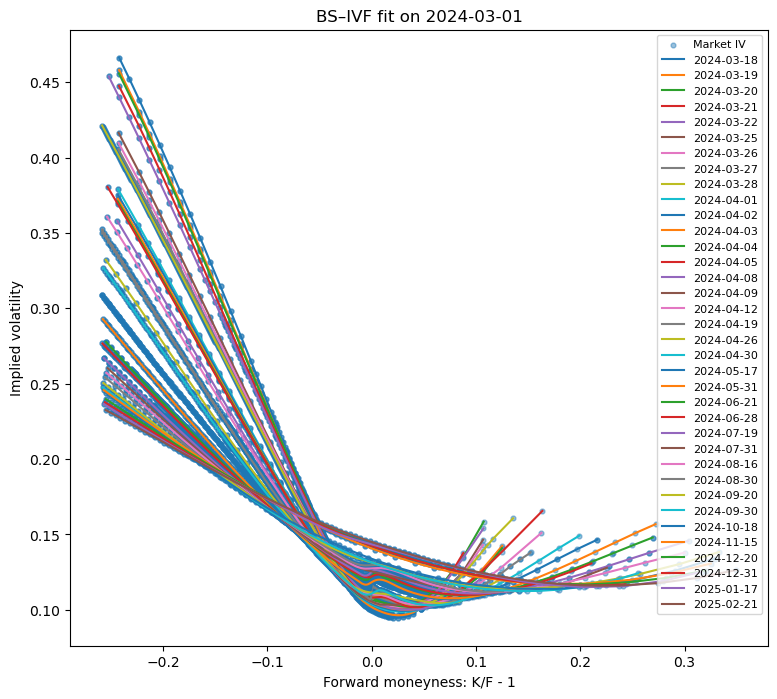

In [22]:
example_date = spline_quotes["date"].min()

example = spline_quotes[
    spline_quotes["date"] == example_date
].copy()

plt.figure(figsize=(9, 8))

plt.scatter(
    example["moneyness"],
    example["spline_iv"],
    s=12,
    alpha=0.45,
    label="Market IV",
)

for exdate, expiry_options in example.groupby("exdate"):
    expiry_options = expiry_options.sort_values("moneyness")

    plt.plot(
        expiry_options["moneyness"],
        expiry_options["spline_iv"],
        linewidth=1.5,
        label=str(exdate.date()),
    )

plt.title(f"BS–IVF fit on {example_date.date()}")
plt.xlabel("Forward moneyness: K/F - 1")
plt.ylabel("Implied volatility")
plt.legend(fontsize=8)
plt.show()

## Interpretation

The main result is the Dumas ad hoc Model S polynomial.

It is intentionally a cheap empirical benchmark rather than a coherent risk-neutral dynamics model:

- it can smooth observed IV;
- it can generate BS prices and plug-in deltas;
- it does not guarantee absence of butterfly or calendar arbitrage;
- its frozen next-day performance tests whether today's cross-sectional relationship remains useful tomorrow.

The optional spline asks a narrower diagnostic question: how much of Model S's error is caused by polynomial stiffness?

# Loading all four BS result tables

In [23]:
# ============================================================
# Final BS comparison on one common pair universe
# ============================================================

# Only load the columns required for the comparison.
# This avoids loading every column from the large result CSVs.
comparison_columns = [
    "pair_id",
    "cp_flag",
    "option_change",
    "best_bid_next",
    "best_offer_next",
    "predicted_price_next",
    "next_day_price_error",
    "hedging_error",
]


bs_results = {
    "Flat BS": pd.read_csv(
        "flat_bs_outputs/flat_bs_pair_results.csv",
        usecols=comparison_columns,
    ),

    "Fan-style contract IV BS": pd.read_csv(
        "flat_bs_outputs/fan_bs_pair_results.csv",
        usecols=comparison_columns,
    ),

    "Dumas Model S": pd.read_csv(
        "ad_hoc_bs_outputs/dumas_model_s_pair_results.csv",
        usecols=comparison_columns,
    ),

    "Cubic spline BS": pd.read_csv(
        "ad_hoc_bs_outputs/optional_spline_pair_results.csv",
        usecols=comparison_columns,
    ),
}


for model_name, model_data in bs_results.items():
    duplicated_pairs = model_data["pair_id"].duplicated().sum()

    if duplicated_pairs > 0:
        raise ValueError(
            f"{model_name} contains "
            f"{duplicated_pairs} duplicated pair_id values."
        )

    print(
        f"{model_name:<30}"
        f"{len(model_data):>10,} pairs"
    )

Flat BS                          224,566 pairs
Fan-style contract IV BS         224,461 pairs
Dumas Model S                    224,566 pairs
Cubic spline BS                  223,866 pairs


# Intersect the pair IDs and calculate final results

In [24]:
common_pair_ids = set(
    bs_results["Flat BS"]["pair_id"]
)

for model_data in bs_results.values():
    common_pair_ids.intersection_update(
        model_data["pair_id"]
    )


common_bs_results = {}

for model_name, model_data in bs_results.items():
    common_bs_results[model_name] = (
        model_data.loc[
            model_data["pair_id"].isin(common_pair_ids)
        ]
        .sort_values("pair_id")
        .reset_index(drop=True)
    )


print()
print(f"Final common number of pairs: {len(common_pair_ids):,}")
print(
    "Spline pairs excluded by the final intersection:",
    f"{len(bs_results['Cubic spline BS']) - len(common_pair_ids):,}",
)


# Confirm that all models now contain exactly the same rows.
reference_model = common_bs_results["Flat BS"]
reference_pair_ids = reference_model["pair_id"].tolist()
reference_option_change = reference_model["option_change"].to_numpy()

for model_name, model_data in common_bs_results.items():

    if model_data["pair_id"].tolist() != reference_pair_ids:
        raise ValueError(
            f"{model_name} does not have the same ordered pair IDs."
        )

    if not np.allclose(
        model_data["option_change"].to_numpy(),
        reference_option_change,
    ):
        raise ValueError(
            f"{model_name} has inconsistent market option changes."
        )


# Overall comparison.
final_bs_comparison = pd.DataFrame(
    {
        model_name: summarise_model(
            model_data,
            price_error_column="next_day_price_error",
            model_price_column="predicted_price_next",
            hedge_error_column="hedging_error",
        )
        for model_name, model_data
        in common_bs_results.items()
    }
).T


display(final_bs_comparison)


# The unhedged MAE must now be identical for all models.
print()
print("Unhedged MAE by model:")

for model_name, model_data in common_bs_results.items():
    print(
        f"{model_name:<30}"
        f"{model_data['option_change'].abs().mean():.8f}"
    )


Final common number of pairs: 223,826
Spline pairs excluded by the final intersection: 40


,number_of_pairs,next_day_price_rmse,next_day_price_mae,next_day_inside_bid_ask,next_day_outside_spread_mae,unhedged_mae,hedging_rmse,hedging_mae,hedging_bias,hedging_improvement
Flat BS,223826.0,19.227321,14.536121,0.036743,12.862413,13.061692,2.500960,1.884862,-0.325305,0.855695
Fan-style contract IV BS,223826.0,5.779579,4.404685,0.308257,3.366540,13.061692,2.355301,1.758561,-0.090633,0.865365
Dumas Model S,223826.0,10.917457,6.918883,0.154495,5.517164,13.061692,2.357996,1.718453,-0.135623,0.868436
Cubic spline BS,223826.0,6.047631,4.344515,0.151158,2.760786,13.061692,2.296599,1.665134,-0.158269,0.872518



Unhedged MAE by model:
Flat BS                       13.06169245
Fan-style contract IV BS      13.06169245
Dumas Model S                 13.06169245
Cubic spline BS               13.06169245


# Call-put comparison and saving the final table

In [25]:
call_put_rows = []

for model_name, model_data in common_bs_results.items():

    for cp_flag, option_type in [
        ("C", "Call"),
        ("P", "Put"),
    ]:
        subset = model_data.loc[
            model_data["cp_flag"].eq(cp_flag)
        ]

        subset_summary = summarise_model(
            subset,
            price_error_column="next_day_price_error",
            model_price_column="predicted_price_next",
            hedge_error_column="hedging_error",
        )

        call_put_rows.append(
            {
                "model": model_name,
                "option_type": option_type,
                **subset_summary.to_dict(),
            }
        )


final_bs_call_put_comparison = (
    pd.DataFrame(call_put_rows)
    .set_index(["model", "option_type"])
)


display(
    final_bs_call_put_comparison[
        [
            "number_of_pairs",
            "next_day_price_rmse",
            "next_day_price_mae",
            "hedging_rmse",
            "hedging_mae",
            "hedging_bias",
            "hedging_improvement",
        ]
    ]
)


comparison_output_folder = Path("ad_hoc_bs_outputs")
comparison_output_folder.mkdir(exist_ok=True)

final_bs_comparison.to_csv(
    comparison_output_folder
    / "final_all_bs_common_pair_comparison.csv"
)

final_bs_call_put_comparison.to_csv(
    comparison_output_folder
    / "final_all_bs_call_put_comparison.csv"
)

pd.Series(
    sorted(common_pair_ids),
    name="pair_id",
).to_csv(
    comparison_output_folder
    / "final_all_bs_common_pair_ids.csv",
    index=False,
)

print(
    "Saved final BS comparison to:",
    comparison_output_folder.resolve(),
)

number_of_pairs  next_day_price_rmse  next_day_price_mae  hedging_rmse  hedging_mae  hedging_bias  hedging_improvement
model                    option_type                                                                                                                        
Flat BS                  Call                115508.0            20.422080           15.434170      2.954561     2.356628     -0.589833             0.874236
                         Put                 108318.0            17.865441           13.578461      1.901554     1.381779     -0.043217             0.802832
Fan-style contract IV BS Call                115508.0             2.421380            1.920289      2.741871     2.101071     -0.357531             0.887874
                         Put                 108318.0             7.922884            7.053992      1.856405     1.393317      0.193982             0.801186
Dumas Model S            Call                115508.0            12.345922            8.057949      2.777719     2.160879     -0.401373             0.884682
                         Put                 108318.0             9.151730            5.704208      1.805957     1.246659      0.147768             0.822112
Cubic spline BS          Call                115508.0             7.177492            5.770193      2.733848     2.120929     -0.423121             0.886814
                         Put                 108318.0             4.543064            2.824203      1.711377     1.179084      0.124164             0.831755

Saved final BS comparison to: C:\Users\Startklar\ICL\NDEs\Codes\BS-IVF\ad_hoc_bs_outputs
